In [1]:
%matplotlib inline
from pathlib import Path
import shutil
import os
import random
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from pprint import pprint
import utils as course_utils

# ======== Your controls: change these to run the notebook your way ========
# True: a small run on a tiny generated sample of ratings; grading always
# uses it. False: MovieLens (downloaded once, about 1 MB) and the settings
# below.
IS_UNITTEST = False
# Directory containing ratings.csv and movies.csv; None downloads MovieLens latest-small.
MOVIELENS_DIR = None
# Number of users to read from MovieLens; increase for more training data.
MAX_USERS = 610
# Number of most-rated movies kept from those users; increase for more candidates.
MAX_MOVIES = 1000
# Maximum training preference pairs sampled per user; increase for more data.
MAX_PAIRS_PER_USER = 1000
# Number of passes through the training pairs for each model; increase for better fitting.
EPOCHS = 12
# Dimension of each learned user and movie taste vector.
EMBEDDING_DIM = 32
# Rating gap required before one movie is considered preferred to another.
RATING_MARGIN = 0.75
# ==========================================================================
# Grading always uses the small run, whatever IS_UNITTEST is set to above.
IS_UNITTEST = IS_UNITTEST or course_utils.checker.is_unittest_run()
# Thread count changes the order of float sums; the small run must
# repeat the teacher's numbers on any machine.
if IS_UNITTEST:
    torch.set_num_threads(1)


seed = int(course_utils.checker.load_answer('xinputs.npz')['seed'])

import source
src = source.code.src
movie_recommendation = src.datasets.movie_recommendation
answer = {}


# Movie Recommendation: Quality and Taste

A recommender orders movies for a user. We explain a user's ratings with
two parts:

1. **Quality:** one number $q_m$ per movie, the same for every user. Some
   movies are simply liked more than others.
2. **Taste:** a vector $e_u$ for every user and $e_m$ for every movie; their
   dot product says how much this user likes this kind of movie.

$$s(u, m) = q_m + e_u \cdot e_m.$$

One model holds all three: the quality vector, the user vectors and the
movie vectors. We train it in two stages: first only the quality, then
only the vectors, with the quality fixed. The vectors then hold only what
the quality does not explain, so movies with similar vectors are liked by
the same kind of people, not just liked by everybody.

Training uses **preferences**: for two movies the same user rated, the one
with more stars should get the higher score.

**Files to edit:**
- [src/datasets/movie_recommendation.py](../../source/code/src/datasets/movie_recommendation.py): the dataset of preference pairs;
- [src/models/feedforward/recommendation.py](../../source/code/src/models/feedforward/recommendation.py): the model;
- the marked cells of this notebook: the loss, the metric, and training the quality.


# Task 0: Prepare the Environment

## Goal

Set all random seeds with `src.utils.seed.seed_all(0)`. Determinism matters here because the preference pairs are sampled at random.


In [2]:
# Edit this cell in task.ipynb.
src.utils.seed.seed_all(0)

seed_check = {
    'python.random': [random.random() for _ in range(3)],
    'numpy.random.rand': np.random.rand(2, 2),
    'torch.rand': torch.rand(2, 2),
}
answer['seed_check'] = seed_check
pprint(seed_check)


{'numpy.random.rand': array([[0.5488135 , 0.71518937],
       [0.60276338, 0.54488318]]),
 'python.random': [0.8444218515250481, 0.7579544029403025, 0.420571580830845],
 'torch.rand': tensor([[0.4963, 0.7682],
        [0.0885, 0.1320]])}


In [3]:
course_utils.checker.print_progress(
    'Task 0: Prepare the Environment', answer,
    prefixes=('seed_check',),
    is_small_run=IS_UNITTEST)


Task 0: Prepare the Environment
  – full run: public answers match the small run only (IS_UNITTEST = True)


# The Data

A full run uses the [MovieLens latest-small dataset](https://grouplens.org/datasets/movielens/):
about 100,000 ratings from 0.5 to 5 stars. The small run uses 12 generated
users with three tastes and 24 movies of three genres. Both are loaded by
`src.datasets.movie_recommendation.load_movielens`, which returns a dict:

- `'train_ratings'`: a list of `(user_id, movie_id, rating)`;
- `'heldout_ratings'`: about a fifth of every user's ratings, in the same
  form, kept out of training. They belong to the same users and movies: they
  check whether the model orders ratings it has not seen;
- `'movies'`: `movies[movie_id]` is `{'title': ..., 'genres': ...}`;
- `'num_users'`, `'num_movies'`: ids run from 0 to these numbers minus one.

Ratings are **sparse**: a missing rating does not mean the user disliked the movie.


610 users, 1000 movies, 49251 training and 12005 held-out ratings
first ratings (user_id, movie_id, stars): [(0, 61, 5.0), (0, 35, 4.0), (0, 611, 5.0)]


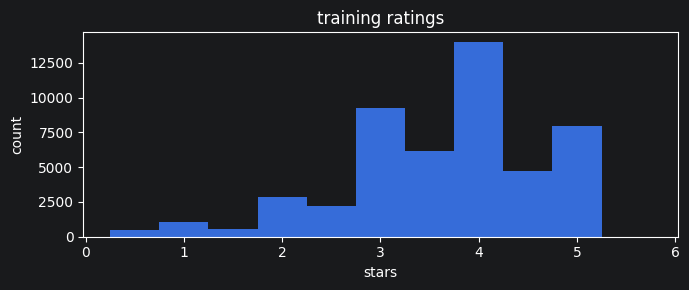

In [4]:
if IS_UNITTEST:
    # The small run uses fixed settings, so grading does not depend on the ones above.
    MAX_PAIRS_PER_USER, EPOCHS, EMBEDDING_DIM, RATING_MARGIN = 64, 30, 8, 0.75
batch_size = 64 if IS_UNITTEST else 1024

movielens = src.datasets.movie_recommendation.load_movielens(
    small=IS_UNITTEST, seed=seed, max_users=MAX_USERS, max_movies=MAX_MOVIES,
    data_dir=MOVIELENS_DIR)
train_ratings = movielens['train_ratings']
heldout_ratings = movielens['heldout_ratings']
movies = movielens['movies']

print(f"{movielens['num_users']} users, {movielens['num_movies']} movies, "
      f"{len(train_ratings)} training and {len(heldout_ratings)} held-out ratings")
print('first ratings (user_id, movie_id, stars):', train_ratings[:3])

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([rating for _, _, rating in train_ratings], bins=np.arange(0.25, 5.76, 0.5))
ax.set_title('training ratings')
ax.set_xlabel('stars')
ax.set_ylabel('count')
plt.tight_layout()
plt.show()


# Task 1: Prepare the Dataset Class

## Goal

Implement `PairwiseMovieDataset` in [src/datasets/movie_recommendation.py](../../source/code/src/datasets/movie_recommendation.py).
It is a PyTorch dataset, like `MNISTSimpleDataset`, but its items are
**preference pairs** instead of images.

## Methods To Implement

- `__init__`: the ratings are already grouped by user. For every user,
  append `(user_id, positive_movie_id, negative_movie_id)` to `user_pairs`
  for **every** two movies of that user where
  `positive_rating >= negative_rating + margin`. The code after your part
  keeps at most `max_pairs_per_user` random pairs per user.
- `__len__`: the number of pairs.
- `__getitem__(index)`: a dict with keys `user_id`, `positive_movie_id`,
  `negative_movie_id`, each a 0-dimensional `torch.long` tensor.

The held-out pairs are made with your class too: all pairs of a user's
ratings in which at least one rating is held out.


In [5]:
# Edit: ../../source/code/src/datasets/movie_recommendation.py
train_dataset = src.datasets.movie_recommendation.PairwiseMovieDataset(
    train_ratings, margin=RATING_MARGIN, max_pairs_per_user=MAX_PAIRS_PER_USER, seed=0)
# ^^^ This class should be implemented in this task
heldout_dataset = src.datasets.movie_recommendation.make_heldout_dataset(
    train_ratings, heldout_ratings, margin=RATING_MARGIN)

print('training pairs:', len(train_dataset), 'held-out pairs:', len(heldout_dataset.samples))
pprint([train_dataset[index] for index in range(3)])

answer['dataset'] = {
    'num_train_pairs': len(train_dataset),
    'num_heldout_pairs': len(heldout_dataset.samples),
    'first_pairs': [train_dataset[index] for index in range(3)],
}


training pairs: 339228 held-out pairs: 1415468
[{'negative_movie_id': tensor(132),
  'positive_movie_id': tensor(152),
  'user_id': tensor(0)},
 {'negative_movie_id': tensor(168),
  'positive_movie_id': tensor(211),
  'user_id': tensor(0)},
 {'negative_movie_id': tensor(173),
  'positive_movie_id': tensor(590),
  'user_id': tensor(0)}]


In [6]:
course_utils.checker.print_progress(
    'Task 1: Prepare the Dataset Class', answer,
    prefixes=('dataset',),
    is_small_run=IS_UNITTEST)


Task 1: Prepare the Dataset Class
  – full run: public answers match the small run only (IS_UNITTEST = True)


# Task 2: Build the Model

## Goal

Implement `MovieRecommender.score` in [src/models/feedforward/recommendation.py](../../source/code/src/models/feedforward/recommendation.py):

$$s(u, m) = q_m + e_u \cdot e_m,$$

where $q_m$ is the entry of `self.quality` for the movie, and
$e_u \cdot e_m$ is the sum of the element-wise products of the user's
and the movie's vectors (`self.user_embedding`, `self.movie_embedding`).
Return one score per pair, shape `(batch,)`, without `sigmoid`: the loss
in Task 3 applies it to a **difference** of scores.

`forward` is given and follows the batch protocol: it calls `self.score`
for the positive and the negative movie of every pair and writes
`batch['signals']['positive_score']` and `batch['signals']['negative_score']`.

The movie vectors start at zero, so a new model scores movies by quality
only; the user vectors start small and random.


In [7]:
# Edit: ../../source/code/src/models/feedforward/recommendation.py
recommendation = src.models.feedforward.recommendation
check_model = recommendation.MovieRecommender(
    movielens['num_users'], movielens['num_movies'], embedding_dim=EMBEDDING_DIM)
# ^^^ This class should be implemented in this task

# Predictable weights, so the scores below can be compared with the answer.
src.utils.deterministic_init(check_model)

check_batch = {'data': {
    'user_id': torch.tensor([0, 0, 1, 2]),
    'positive_movie_id': torch.tensor([0, 1, 2, 3]),
    'negative_movie_id': torch.tensor([4, 5, 6, 7]),
}}
check_model(check_batch)
print('scores:', check_batch['signals'])
answer['check_batch'] = dict(check_batch['signals'])


scores: {'positive_score': tensor([-0.0026, -0.0025, -0.0058, -0.0091], grad_fn=<AddBackward0>), 'negative_score': tensor([-0.0025, -0.0025, -0.0058, -0.0090], grad_fn=<AddBackward0>)}


In [8]:
course_utils.checker.print_progress(
    'Task 2: Build the Model', answer,
    prefixes=('check_batch',),
    is_small_run=IS_UNITTEST)


Task 2: Build the Model
  – full run: public answers match the small run only (IS_UNITTEST = True)


# Task 3: Create the Pairwise Loss and the Pairwise Accuracy

## Pairwise Loss

For a pair, the difference of scores is the **preference logit**:
$z = s(u, m^+) - s(u, m^-)$, and $\sigma(z)$ is the predicted probability
that the user prefers $m^+$ to $m^-$. The loss is the negative log of that
probability, averaged over the batch:

$$L = \frac{1}{N} \sum_{i=1}^{N} -\log \sigma(z_i) = \frac{1}{N} \sum_{i=1}^{N} \mathrm{softplus}(-z_i).$$

Use `torch.nn.functional.softplus`: it computes $\log(1 + e^{x})$ without overflow.

## Pairwise Accuracy

The fraction of pairs in which the preferred movie gets the higher score:

$$\mathrm{accuracy} = \frac{1}{N} \sum_{i=1}^{N} [\, s(u, m^+_i) > s(u, m^-_i) \,].$$

Like `accuracy` in the Shallow Feedforward NNs task, return the numerator
and the denominator, so that `train_model` can sum them over all batches.


In [9]:
# Edit this cell in task.ipynb.
def pairwise_loss(batch):
    preference_logit = batch['signals']['positive_score'] - batch['signals']['negative_score']
    return F.softplus(-preference_logit).mean()


def pairwise_accuracy(batch):
    correct = (batch['signals']['positive_score'] > batch['signals']['negative_score']).sum().float()
    total = batch['signals']['positive_score'].shape[0]
    return correct, total

losses = {'pairwise': pairwise_loss}
metrics = {'pairwise_accuracy': pairwise_accuracy}

# A fixed batch of scores: the first two pairs are ordered right, the third is not.
scored_batch = {'signals': {
    'positive_score': torch.tensor([2.0, 0.5, -1.0]),
    'negative_score': torch.tensor([0.0, 0.0, 1.0]),
}}
answer['test_loss_val'] = {name: fn(scored_batch) for name, fn in losses.items()}
answer['test_metrics_val'] = {name: fn(scored_batch) for name, fn in metrics.items()}
pprint(answer['test_loss_val'])
pprint(answer['test_metrics_val'])


{'pairwise': tensor(0.9093)}
{'pairwise_accuracy': (tensor(2.), 3)}


In [10]:
course_utils.checker.print_progress(
    'Task 3: Create the Pairwise Loss and the Pairwise Accuracy', answer,
    prefixes=('test_loss_val', 'test_metrics_val'),
    is_small_run=IS_UNITTEST)


Task 3: Create the Pairwise Loss and the Pairwise Accuracy
  – full run: public answers match the small run only (IS_UNITTEST = True)


# Task 4: Train the Movie Quality

## Goal

Train only the quality of `model` with `src.train_loop.train_model`, the
training loop from the Shallow Feedforward NNs task:

- optimizer: `torch.optim.AdamW` over `[model.quality]` only, with
  `lr=5.0e-2` and `weight_decay=1.0e-4`: an optimizer changes only the
  parameters it is given, so the vectors stay as they are (the movie
  vectors stay zero);
- `EPOCHS` epochs on `train_dl`, with `losses` and `metrics` from Task 3;
- no validation set: pass `None` as `valid_dl`; we check the held-out
  pairs separately below.

Store the result of `train_model` in `quality_history`.

After training, the highest quality should go to movies that almost
everybody rates high.


In [11]:
# Edit this cell in task.ipynb.
train_dl = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(0))
src.utils.seed.seed_all(0)
model = recommendation.MovieRecommender(
    movielens['num_users'], movielens['num_movies'], embedding_dim=EMBEDDING_DIM)

optimizer = torch.optim.AdamW([model.quality], lr=5.0e-2, weight_decay=1.0e-4)
quality_history = src.train_loop.train_model(
    model, EPOCHS, train_dl, None, losses, optimizer, metrics=metrics, run_name='movie quality')

# The held-out pairs, while the model knows only the quality.
heldout = {'quality only': recommendation.evaluate_pairs(
    model, heldout_dataset, pairwise_loss, pairwise_accuracy)}

best_movies = model.quality.detach().argsort(descending=True)[:10].tolist()
print('Highest quality:')
for movie_id in best_movies:
    print(f"    {movies[movie_id]['title']}")

answer['quality_training'] = {
    'loss': quality_history['train_loss']['pairwise'],
    'accuracy': quality_history['train_metrics']['pairwise_accuracy'],
    'best_movies': best_movies,
}


epochs:   0%|          | 0/12 [00:00<?, ?it/s]

batches:   0%|          | 0/332 [00:00<?, ?it/s]

Highest quality:
    Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)
    Patton (1970)
    Wallace & Gromit: The Best of Aardman Animation (1996)
    Philadelphia Story, The (1940)
    Lawrence of Arabia (1962)
    There Will Be Blood (2007)
    Evil Dead II (Dead by Dawn) (1987)
    Intouchables (2011)
    Departed, The (2006)
    Casablanca (1942)


In [12]:
course_utils.checker.print_progress(
    'Task 4: Train the Movie Quality', answer,
    prefixes=('quality_training',),
    is_small_run=IS_UNITTEST)


Task 4: Train the Movie Quality
  – full run: public answers match the small run only (IS_UNITTEST = True)


# Training the Taste Vectors

Now the same model trains only its user and movie vectors, with the same
loop; the optimizer does not get `model.quality`, so the quality stays
fixed. The weight decay
is strong on purpose: every user and every movie has its own vector, fitted
from a few dozen ratings, and without it the vectors memorize the training
pairs instead of learning tastes (the held-out loss below would show it).

Then we compare both models on the **held-out** pairs: how often the order
of the two movies is right, and the loss averaged **per movie** (every
movie's mean loss over its held-out pairs, then the mean over movies), so
that the most rated movies do not dominate it.


epochs:   0%|          | 0/12 [00:00<?, ?it/s]

batches:   0%|          | 0/332 [00:00<?, ?it/s]

quality only     held-out order accuracy 0.719, loss per movie 0.559
quality + taste  held-out order accuracy 0.811, loss per movie 0.419


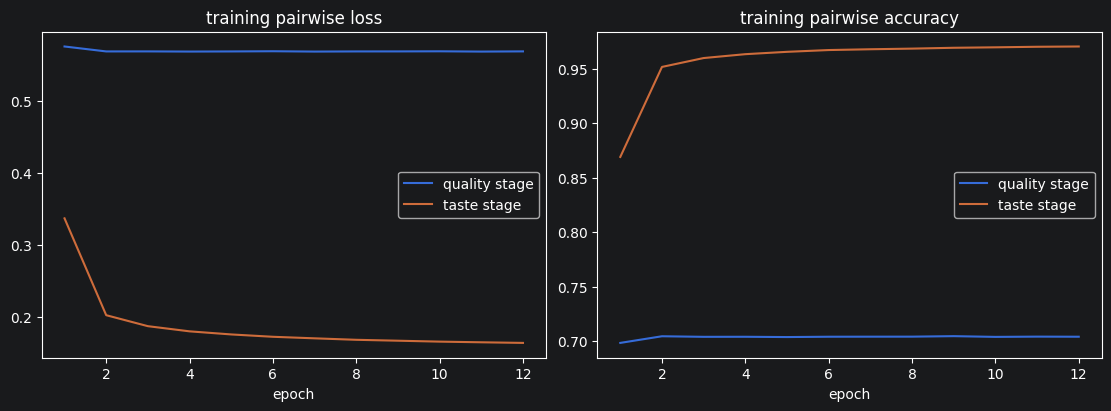

In [13]:
optimizer = torch.optim.AdamW(
    [model.user_embedding.weight, model.movie_embedding.weight], lr=1.0e-2, weight_decay=0.5)
taste_history = src.train_loop.train_model(
    model, EPOCHS, train_dl, None, losses, optimizer,
    metrics=metrics, run_name='movie taste')

heldout['quality + taste'] = recommendation.evaluate_pairs(
    model, heldout_dataset, pairwise_loss, pairwise_accuracy)
for name, result in heldout.items():
    print(f"{name:16s} held-out order accuracy {result['accuracy']:.3f}, "
          f"loss per movie {result['loss_per_movie']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for name, history in [('quality stage', quality_history), ('taste stage', taste_history)]:
    epochs = range(1, len(history['train_loss']['pairwise']) + 1)
    axes[0].plot(epochs, history['train_loss']['pairwise'], label=name)
    axes[1].plot(epochs, history['train_metrics']['pairwise_accuracy'], label=name)
axes[0].set_title('training pairwise loss')
axes[1].set_title('training pairwise accuracy')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend()
plt.show()

answer['taste_training'] = {
    'loss': taste_history['train_loss']['pairwise'],
    'accuracy': taste_history['train_metrics']['pairwise_accuracy'],
}
answer['heldout'] = heldout


In [14]:
course_utils.checker.print_progress(
    'Training the Taste Vectors', answer,
    prefixes=('taste_training', 'heldout'),
    is_small_run=IS_UNITTEST)


Training the Taste Vectors
  – full run: public answers match the small run only (IS_UNITTEST = True)


# What the Model Learned

Two very different audiences: fans of **Star Wars** and fans of **Gone with
the Wind**. For a fan of each, we show the movies they rated highest and
two recommendations among the movies they have **not** rated:

- by the full score, quality + taste: what the model expects them to rate
  highest, usually movies that almost everybody rates high;
- by the taste part alone: what fits *this* user, whatever the overall quality.

Then the movies whose taste vectors are closest to each of the two films.

The small run has no real titles: its action movies play Star Wars and its
dramas play Gone with the Wind.


In [15]:
ratings_by_user = src.datasets.movie_recommendation.group_by_user(train_ratings + heldout_ratings)
user_vectors = model.user_embedding.weight.detach()
movie_vectors = model.movie_embedding.weight.detach()

if IS_UNITTEST:
    first_movies = [i for i, movie in enumerate(movies) if movie['genres'] == 'Action']
    second_movies = [i for i, movie in enumerate(movies) if movie['genres'] == 'Drama']
else:
    first_movies = [i for i, movie in enumerate(movies) if movie['title'].startswith('Star Wars')]
    second_movies = [i for i, movie in enumerate(movies) if movie['title'].startswith('Gone with the Wind')]


def mean_rating(user_id, movie_ids):
    rated = dict(ratings_by_user[user_id])
    stars = [rated[movie_id] for movie_id in movie_ids if movie_id in rated]
    return sum(stars) / len(stars) if stars else 0.0


def find_fan(liked_movies, other_movies):
    # Rates the liked movies 4.5 stars or more and does not love the other
    # ones; of those, the user whose taste vector points most towards them.
    candidates = [user_id for user_id in ratings_by_user
                  if mean_rating(user_id, liked_movies) >= 4.5
                  and mean_rating(user_id, other_movies) < 4.0]
    taste = user_vectors @ movie_vectors[liked_movies].mean(dim=0)
    return max(candidates, key=lambda user_id: float(taste[user_id]))


def show_fan(title, user_id, fan_movies):
    # The movies the user is a fan of come first, then the rest by stars.
    rated = sorted(ratings_by_user[user_id],
                   key=lambda pair: (pair[0] not in fan_movies, -pair[1]))
    liked = [movie_id for movie_id, rating in rated if rating >= 4.0][:5]
    seen = [movie_id for movie_id, _ in rated]
    best = recommendation.recommend(model, user_id, seen_movie_ids=seen, k=5)
    closest = recommendation.recommend(model, user_id, seen_movie_ids=seen, k=5,
                                       use_quality=False)
    print(f'{title}: user {user_id}')
    for heading, movie_ids in [('liked', liked),
                               ('recommended, quality + taste', best),
                               ('recommended, taste only', closest)]:
        print(f'  {heading}:')
        for movie_id in movie_ids:
            print(f"    {movies[movie_id]['title']}")
    return {'user_id': user_id, 'liked': liked, 'best': best, 'closest': closest}


answer['demo'] = {
    'first_fan': show_fan('A Star Wars fan', find_fan(first_movies, second_movies), first_movies),
    'second_fan': show_fan('A Gone with the Wind fan', find_fan(second_movies, first_movies), second_movies),
}


A Star Wars fan: user 209
  liked:
    Star Wars: Episode V - The Empire Strikes Back (1980)
    Star Wars: Episode IV - A New Hope (1977)
    Star Wars: Episode II - Attack of the Clones (2002)
    Star Wars: Episode I - The Phantom Menace (1999)
    Star Wars: Episode VI - Return of the Jedi (1983)
  recommended, quality + taste:
    Intouchables (2011)
    Philadelphia Story, The (1940)
    Schindler's List (1993)
    Wallace & Gromit: The Best of Aardman Animation (1996)
    Lawrence of Arabia (1962)
  recommended, taste only:
    Mr. Holland's Opus (1995)
    Minority Report (2002)
    Harry Potter and the Prisoner of Azkaban (2004)
    Clerks (1994)
    Schindler's List (1993)
A Gone with the Wind fan: user 139
  liked:
    Gone with the Wind (1939)
    Hunt for Red October, The (1990)
    My Big Fat Greek Wedding (2002)
    Enemy at the Gates (2001)
    Pretty Woman (1990)
  recommended, quality + taste:
    Singin' in the Rain (1952)
    Manchurian Candidate, The (1962)
    Phi

In [16]:
answer['demo']['similar_movies'] = {}
for name, movie_id in [('first', first_movies[0]), ('second', second_movies[0])]:
    similar = recommendation.most_similar(movie_vectors, movie_id, k=5)
    print(f"Movies with a taste vector close to {movies[movie_id]['title']}:")
    for similar_id in similar:
        print(f"    {movies[similar_id]['title']}")
    answer['demo']['similar_movies'][name] = similar


Movies with a taste vector close to Star Wars: Episode IV - A New Hope (1977):
    Star Wars: Episode V - The Empire Strikes Back (1980)
    Star Wars: Episode VI - Return of the Jedi (1983)
    Star Trek II: The Wrath of Khan (1982)
    Muppet Movie, The (1979)
    Shakespeare in Love (1998)
Movies with a taste vector close to Gone with the Wind (1939):
    Robin Hood (1973)
    Ferris Bueller's Day Off (1986)
    Cocoon (1985)
    Great Escape, The (1963)
    Sting, The (1973)


In [17]:
course_utils.checker.print_progress(
    'What the Model Learned', answer,
    prefixes=('demo',),
    is_small_run=IS_UNITTEST)


What the Model Learned
  – full run: public answers match the small run only (IS_UNITTEST = True)


# What to Try Next

Set `IS_UNITTEST = False` for the real MovieLens data, then try a different
`EMBEDDING_DIM`, more `EPOCHS`, or other weight decays for the taste vectors,
and watch the held-out loss. You can point `MOVIELENS_DIR` to an extracted
[MovieLens 32M](https://grouplens.org/datasets/movielens/) folder.


In [18]:
course_utils.checker.save_answer(answer)
